# NMR：从自由感应衰减到频谱

这是明确给出参数的物理教学模拟，没有使用实验测量，也不作为模型基准。可修改参数并重新执行，观察结果变化。

In [1]:
import io, json, sys
from pathlib import Path
from IPython.display import display, SVG
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'openmolspec_bench').is_dir())
sys.path.insert(0, str(root/'src'))
import matplotlib.pyplot as plt
from openmolspec.plotting import figure_style
figure_style()
blue, teal, grey = '#397BA6', '#178F88', '#A8B3BF'


Input frequencies (Hz): [80.0, 145.0, 210.0]


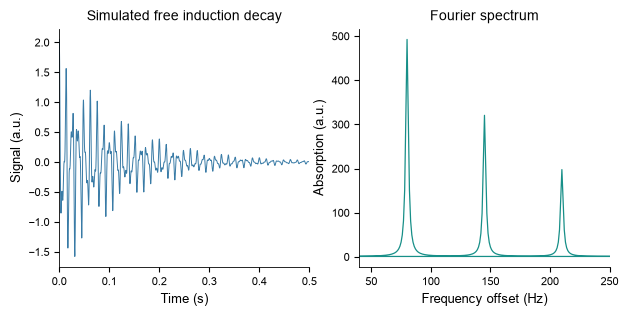

In [2]:
import numpy as np
time = np.arange(4096) / 4096
frequencies = np.array([80., 145., 210.])
amplitudes = np.array([1., .65, .4])
signal = sum(a*np.exp(-time/.12)*np.exp(2j*np.pi*f*time) for a,f in zip(amplitudes,frequencies))
axis = np.fft.fftfreq(len(time), time[1]-time[0])
spectrum = np.fft.fft(signal).real
assert abs(axis[np.argmax(spectrum)] - 80) < 1.1
fig, axes = plt.subplots(1, 2, figsize=(7.1, 3.1))
axes[0].plot(time, signal.real, color=blue, lw=.7)
axes[0].set(xlabel='Time (s)', ylabel='Signal (a.u.)', xlim=(0, .5), title='Simulated free induction decay')
axes[1].plot(axis, spectrum, color=teal, lw=.9)
axes[1].set(xlabel='Frequency offset (Hz)', ylabel='Absorption (a.u.)', xlim=(40,250), title='Fourier spectrum')
print('Input frequencies (Hz):', frequencies.tolist())

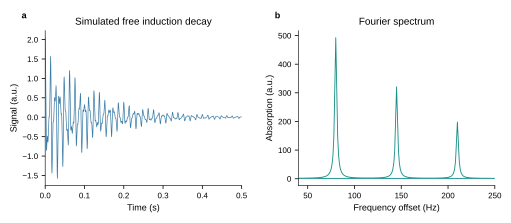

In [3]:
for index, ax in enumerate(axes):
    ax.text(-.12,1.08,chr(97+index),transform=ax.transAxes,fontsize=9,weight='bold')
fig.tight_layout(w_pad=2)
image=io.StringIO()
fig.savefig(image,format='svg',metadata={'Date':None})
display(SVG(image.getvalue()))
plt.close(fig)

[Theory](../theory/index.md) · [Inversion](../inversion/index.md) · [Tutorials](index.md)